<a href="https://colab.research.google.com/github/rahulsanjay009/rl-memory-profiling/blob/main/notebooks/01_trl_baseline_profile.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RL Post-Training GPU Memory Profile (TRL track)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rahulsanjay009/rl-memory-profiling/blob/main/notebooks/01_trl_baseline_profile.ipynb)

Runs a small GRPO run (TRL + Qwen2.5-0.5B-Instruct) on a single GPU, tags each step's rollout (completion sampling) and update (loss/backward/optimizer) phases, and measures:

1. the memory-vs-time profile across phases,
2. a parameter / gradient / optimizer-state breakdown at representative checkpoints, and
3. an idle-time estimate per category.

**Why GRPO and not PPO:** TRL's classic `PPOTrainer`/`AutoModelForCausalLMWithValueHead` have been moved into `trl.experimental.ppo`, with a much heavier setup (separate reward model, value model, and training dataset). `GRPOTrainer` is TRL's current primary on-policy trainer, and it's simpler to set up too (a plain reward function, no separate value model). It's also more representative of what modern RL post-training systems, including veRL cited below, actually run.

See the repo [README](https://github.com/rahulsanjay009/rl-memory-profiling) for the full plan and cited related work.

In [19]:
import os, sys

repo_dir = "rl-memory-profiling"

if not os.path.exists(repo_dir):
    !git clone https://github.com/rahulsanjay009/rl-memory-profiling.git

!pip install -q trl transformers torch pandas matplotlib

scripts_dir = os.path.abspath(os.path.join(repo_dir, "scripts"))
assert os.path.exists(os.path.join(scripts_dir, "memory_poller.py")), f"memory_poller.py not found in {scripts_dir}"
sys.path.insert(0, scripts_dir)

from memory_poller import MemoryPoller, compute_category_breakdown

## 0. GPU check

Needs a GPU runtime: Runtime → Change runtime type → Hardware accelerator → GPU.

In [ ]:
import torch

assert torch.cuda.is_available(), "No GPU detected. Set Runtime > Change runtime type > GPU, then re-run from the top."
print(torch.cuda.get_device_name(0))

## 1. Build the GRPO trainer

`reward_funcs` can be a plain Python callable. It receives `completions` and must return one float per completion. The reward here is a placeholder (rewards longer completions), it just needs to be *something* that drives generation and a policy update each step, since this notebook measures memory shape, not training quality.

In [21]:
from datasets import Dataset
from trl import GRPOConfig, GRPOTrainer

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"


def placeholder_reward(completions, **kwargs):
    """Rewards longer completions. Only used to drive a policy update for profiling purposes."""
    return [float(len(c)) for c in completions]


prompts = [
    "Explain why the sky is blue.",
    "Explain why ice floats on water.",
    "Explain what causes seasons.",
    "Explain why metals conduct electricity.",
]
dataset = Dataset.from_dict({"prompt": prompts * 4})  # repeated so a few steps have data to cycle through

NUM_GENERATIONS = 4

training_args = GRPOConfig(
    output_dir="grpo-memory-profile",
    max_steps=10,
    per_device_train_batch_size=NUM_GENERATIONS,
    num_generations=NUM_GENERATIONS,
    max_completion_length=64,
    logging_steps=1,
    report_to="none",
    bf16=False,
    fp16=True,  # T4 (Colab free tier, compute capability 7.5) doesn't support bf16 matmul; fp16 does
)

## 2. Phase-tagged trainer + per-step category breakdown (Experiments 1-2)

`GRPOTrainer._generate_and_score_completions` is where rollout/sampling happens. The rest of `training_step` (loss + backward) is the update. The actual `optimizer.step()` call happens just after `training_step` returns, inside the outer training loop, so the "update" window measured here covers loss + backward but not that final step call.

Two capture points feed the category breakdown:
- `step_begin` / `step_end` (via a `TrainerCallback`) bracket the *outside* of a step. By the time `step_end` fires, the outer loop has already called `optimizer.zero_grad()`, so `gradients` always reads 0 there. These two points are only useful for `parameters`/`optimizer_state`.
- `post_backward` (captured directly inside the subclassed `training_step`, right after `backward()` runs but before the outer loop's `optimizer.step()`/`zero_grad()`) is the only point where `gradients` is actually non-zero.

In [ ]:
from transformers import TrainerCallback

poller = MemoryPoller(interval_s=0.05)
breakdowns = []  # (step, checkpoint_label, category_bytes_dict)


class ProfiledGRPOTrainer(GRPOTrainer):
    def _generate_and_score_completions(self, *args, **kwargs):
        with poller.phase("rollout"):
            return super()._generate_and_score_completions(*args, **kwargs)

    def training_step(self, *args, **kwargs):
        with poller.phase("update"):
            result = super().training_step(*args, **kwargs)
        # captured right after backward(), before the outer loop's optimizer.step() /
        # zero_grad() run. this is the only point where gradients are actually populated
        breakdowns.append((self.state.global_step, "post_backward", compute_category_breakdown(self.model, self.optimizer)))
        return result


class BreakdownCallback(TrainerCallback):
    def on_step_begin(self, args, state, control, **kwargs):
        breakdowns.append((state.global_step, "step_begin", compute_category_breakdown(trainer.model, trainer.optimizer)))

    def on_step_end(self, args, state, control, **kwargs):
        breakdowns.append((state.global_step, "step_end", compute_category_breakdown(trainer.model, trainer.optimizer)))


trainer = ProfiledGRPOTrainer(
    model=MODEL_NAME,
    reward_funcs=placeholder_reward,
    args=training_args,
    train_dataset=dataset,
)
trainer.add_callback(BreakdownCallback())

poller.start()
try:
    trainer.train()
finally:
    poller.stop()

df = poller.to_dataframe()
os.makedirs("../results", exist_ok=True)
poller.to_csv("../results/trl_baseline_trace.csv")
df.tail()

## 3. Baseline phase memory profile (Experiment 1)

In [ ]:
import matplotlib.pyplot as plt

PHASE_COLORS = {"rollout": "#4C72B0", "update": "#DD8452", "overhead": "#B0B0B0"}

df["allocated_gb"] = df["allocated_bytes"] / 1e9

fig, ax = plt.subplots(figsize=(10, 4))
for phase, group in df.groupby("phase"):
    ax.scatter(group["t"], group["allocated_gb"], s=4, label=phase, color=PHASE_COLORS.get(phase, "#333"))
ax.set_xlabel("time (s)")
ax.set_ylabel("GPU memory allocated (GB)")
ax.set_title(f"{MODEL_NAME} - GRPO memory over rollout/update phases")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Memory category breakdown (Experiment 2)

In [24]:
import pandas as pd

bdf = pd.DataFrame(
    [{"step": s, "checkpoint": c, **{k: v / 1e9 for k, v in d.items()}} for s, c, d in breakdowns]
)
avg_by_checkpoint = bdf.groupby("checkpoint")[["parameters", "gradients", "optimizer_state"]].mean()
print("Average category sizes (GB) by checkpoint:")
avg_by_checkpoint

Average category sizes (GB) by checkpoint:


,parameters,gradients,optimizer_state
checkpoint,,,
post_backward,1.976131,1.976131,3.557037
step_begin,1.976131,0.000000,3.557037
step_end,1.976131,0.000000,3.952263


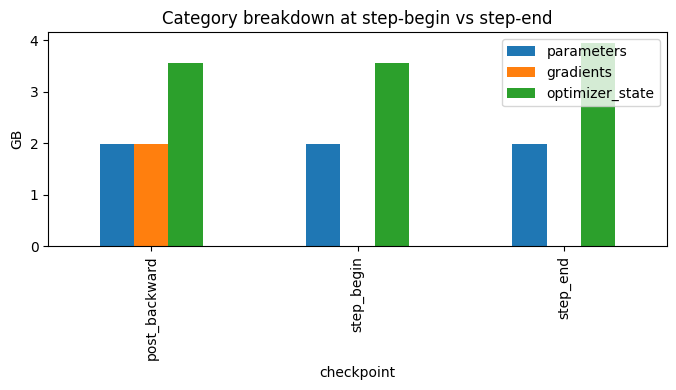

In [25]:
ax = avg_by_checkpoint.plot(kind="bar", figsize=(7, 4))
ax.set_ylabel("GB")
ax.set_title("Category breakdown at step-begin vs step-end")
plt.tight_layout()
plt.show()

## 5. Idle-time characterization (Experiment 3)

Simplifying proxy: during the rollout phase (`_generate_and_score_completions`), nothing calls `optimizer.step()`, so optimizer state is untouched. During the update phase, the rollout's generation buffers aren't reused. Under that assumption, each category's idle time within a step is just the wall-clock time spent in the *other* phase.

The trace's trailing samples are trimmed to the last rollout/update sample first, so the one-time end-of-run checkpoint save (outside any step) doesn't skew the percentages. The remaining `overhead` phase, time tagged neither `rollout` nor `update`, is real per-step cost outside our two tagged windows: mainly the `optimizer.step()` call itself (which falls just after `training_step` returns, per the note in section 2) plus logging/callback/data-loading overhead. That's a different thing from the *category* idle fractions below, don't confuse the small `overhead` percentage with the much larger fraction of the step that a given memory category spends idle.

In [ ]:
non_overhead = df[df["phase"] != "overhead"]
last_active_t = non_overhead["t"].max()
steady_df = df[df["t"] <= last_active_t]  # drop the trailing end-of-run checkpoint-save tail

phase_time = steady_df.groupby("phase")["t"].count() * poller.interval_s  # sample count * interval ≈ wall time
total_time = phase_time.sum()

rollout_time = phase_time.get("rollout", 0.0)
update_time = phase_time.get("update", 0.0)
overhead_time = phase_time.get("overhead", 0.0)

print(f"rollout phase:  {rollout_time:.2f}s ({rollout_time / total_time:.1%} of total)")
print(f"update phase:   {update_time:.2f}s ({update_time / total_time:.1%} of total)")
print(f"overhead phase: {overhead_time:.2f}s ({overhead_time / total_time:.1%} of total)  <- optimizer.step() + per-step bookkeeping, NOT a category idle fraction")
print()
print(f"optimizer_state idle fraction (≈ rollout share): {rollout_time / total_time:.1%}")
print(f"rollout-buffer idle fraction (≈ update share): {update_time / total_time:.1%}")

## Extensions (not run here)

These are left as a roadmap rather than executed here, to keep this repo scoped to what's actually measured above.

- **Experiment 4 (workload sweep):** re-run sections 1-2 with different `num_generations` / `max_completion_length`, and recompute the idle-time split for each config. Expected: the optimizer-state idle fraction (currently ~90% at `num_generations=4` / `max_completion_length=64`) should shift with rollout length. Longer completions push it higher, shorter completions / larger update batches pull it down. The payoff is a workload-dependent curve: empirical evidence that any memory-management decision for this kind of system needs to be workload-aware rather than built around one fixed threshold.
- **Experiment 5 (offload cost baseline):** pass a DeepSpeed ZeRO-Offload config via `GRPOConfig(deepspeed=...)` (or a manual `.to("cpu", non_blocking=True)` round-trip on the optimizer state) and re-measure `update_time`, reproducing ZeRO-Offload/ZenFlow's measurement style. Expected: a concrete per-step latency cost for moving ~4GB of optimizer state to host DRAM and back, the baseline number any future comparison between memory tiers (host DRAM vs. CXL vs. staying GPU-resident) would need as a reference point.
- **Experiment 6 (Nsight annotated timeline):** `nsys profile` with `torch.cuda.nvtx.range_push("rollout")` / `"update"` markers around the same call sites used above. Expected: a kernel-level timeline, finer-grained than the ~50ms Python-level polling used in this notebook, suitable as a standalone figure showing the phase structure at the level individual CUDA kernels execute.
- **Track B (veRL):** see the expanded plan below.

## Track B plan: what running this on veRL would add

Track A above runs entirely in one process, on one GPU. TRL's `GRPOTrainer` generates and updates the same model instance inside the same CUDA context. veRL (HybridFlow), the framework this proposal is actually about, is architected differently: rollout is served by vLLM (typically its own worker), training runs under FSDP or Megatron (its own worker), and Ray orchestrates data between them. veRL supports two deployment modes, and the choice between them changes what "idle" even means here:

- **Colocated**: rollout and training workers share the same GPU(s), taking turns. Architecturally closer to what Track A measures, so the idle-fraction numbers should be *comparable in kind*, though vLLM's own memory pool and FSDP's sharding will likely shift the exact magnitude.
- **Disaggregated**: rollout and training run on *separate* GPUs/nodes at the same time. Here the training GPU's optimizer state isn't just idle for ~90% of a step the way Track A found, it can sit on a GPU doing nothing at all while a different GPU handles rollout. That's a sharper version of the same finding, and it's the deployment mode production-scale RL post-training (and this proposal's premise) is actually most relevant to.

**What would need to happen to run this for real:** a rented multi-GPU box (disaggregated mode needs at least two GPUs to be a meaningful test), installing veRL from source per its own docs, and wiring real phase markers into its rollout/update call sites. `scripts/memory_poller.py`'s `run_verl_track` is left as a documented skeleton rather than guessed code. Unlike TRL, where `_generate_and_score_completions` / `training_step` were confirmed from source before writing this notebook, veRL's exact internal API wasn't verified here, and getting it wrong silently would produce a misleading trace rather than a visible error.

**What a result would need to be a fair comparison to Track A:** the same or a comparably-sized model (Qwen2.5-0.5B, veRL's own quickstart default) and a similar step budget, so any difference in idle fraction reflects the framework's architecture and deployment mode, not a change in model size or workload shape.

See `notebooks/02_verl_phase_analysis.ipynb` for the analysis-side code, already written and ready to run once a real trace exists.

## References

1. Sheng, G. et al. "HybridFlow: A Flexible and Efficient RLHF Framework." EuroSys 2025. [arXiv:2409.19256](https://arxiv.org/abs/2409.19256)
2. Wang, X. et al. "LlamaRL: A Distributed Asynchronous RL Framework for Efficient Large-scale LLM Training." [arXiv:2505.24034](https://arxiv.org/abs/2505.24034)
3. Ren, J. et al. "ZeRO-Offload: Democratizing Billion-Scale Model Training." [arXiv:2101.06840](https://arxiv.org/abs/2101.06840)
4. Lan, T. et al. "ZenFlow: Enabling Stall-Free Offloading Training via Asynchronous Updates." [arXiv:2505.12242](https://arxiv.org/abs/2505.12242)
5. "Rollplex: Cross-Phase GPU Spatial Sharing for Vision Language Model Post-Training." [arXiv:2608.14498](https://arxiv.org/abs/2608.14498)
6. Feng, Y. et al. "Ada-KV: Optimizing KV Cache Eviction by Adaptive Budget Allocation." [arXiv:2407.11550](https://arxiv.org/abs/2407.11550)
7. Wang, X. et al. "Exploring and Evaluating Real-world CXL: Use Cases and System Adoption." IPDPS 2025. [arXiv:2405.14209](https://arxiv.org/abs/2405.14209)